<a href="https://colab.research.google.com/github/sonyadrach/ml/blob/main/ml_lab5_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 5-6
### Нейронна мережа i регуляризацiя
**Мета роботи:** Реалiзувати повнозв’язну нейронну мережу (MLP) з нуля, дослiдити механiзм зворотного поширення помилки, навчитися зберiгати та вiдновлювати параметри нейронної мережi. Експериментально дослiдити вплив рiзних методiв регуляризацiї на розподiл ваг, розрiдженiсть моделi, кiлькiсть неактивних нейронiв та якiсть класифiкацiї.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

print("Завантаження FashionMNIST")
fashion = fetch_openml('Fashion-MNIST', version=1, as_frame=False, parser='auto')
X_all = fashion.data.astype(np.float32) / 255.0  # Нормалізація до [0, 1]
y_all = fashion.target.astype(np.int64)

X_sub, _, y_sub, _ = train_test_split(
    X_all, y_all, train_size=12000, stratify=y_all, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_sub, y_sub, test_size=2000, stratify=y_sub, random_state=SEED
)

print(f"X_train: {X_train.shape}, X_val: {X_val.shape}")
print(f"Діапазон значень: [{X_train.min():.1f}, {X_train.max():.1f}], Класів: {len(np.unique(y_train))}")

Завантаження FashionMNIST
X_train: (10000, 784), X_val: (2000, 784)
Діапазон значень: [0.0, 1.0], Класів: 10


**Висновок:** Датасет FashionMNIST успішно завантажено, пікселі нормалізовано до діапазону [0.0, 1.0], сформовано фіксовані вибірки X_train (10 000 об’єктів) та X_val (2 000 об’єктів) для 10 класів.

## Блок 1. Реалізація нейронної мережі з нуля

Реалізація класу MLP з архітектурою 784 -> 256 -> 128 -> 64 -> 10 (3 приховані шари з ReLU, вихідний шар із Softmax).
Клас одразу підтримує всі механізми для Блоку 2:
- He initialization для ваг;
- Inverted Dropout (вимикається при `training=False`);
- L1 та L2 регуляризацію;
- Weight clipping та Gradient clipping;
- Збереження/завантаження ваг через `np.savez`.

In [2]:
class MLP:
    def __init__(self, layer_sizes, dropout_p=0.0, l1_lambda=0.0, l2_lambda=0.0,
                 weight_clip=None, grad_clip=None, seed=42):

        self.layer_sizes = layer_sizes
        self.num_layers = len(layer_sizes) - 1
        self.dropout_p = dropout_p
        self.l1_lambda = l1_lambda
        self.l2_lambda = l2_lambda
        self.weight_clip = weight_clip
        self.grad_clip = grad_clip
        self.seed = seed

        self.weights = []
        self.biases = []
        self._init_weights()

        self.activations = []
        self.z_values = []
        self.dropout_masks = []

    def _init_weights(self):
        rng = np.random.default_rng(self.seed)
        self.weights = []
        self.biases = []
        for i in range(self.num_layers):
            n_in, n_out = self.layer_sizes[i], self.layer_sizes[i + 1]
            W = rng.normal(0.0, np.sqrt(2.0 / n_in), size=(n_in, n_out))
            b = np.zeros(n_out, dtype=np.float64)
            self.weights.append(W)
            self.biases.append(b)

    def forward(self, X, training=False):
        self.activations = [X]
        self.z_values = []
        self.dropout_masks = []

        A = X
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            Z = A @ W + b
            A = np.maximum(0.0, Z)

            if training and self.dropout_p > 0.0:
                mask = (np.random.rand(*A.shape) >= self.dropout_p).astype(np.float64)
                A = (A * mask) / (1.0 - self.dropout_p)
                self.dropout_masks.append(mask)
            else:
                self.dropout_masks.append(None)

            self.z_values.append(Z)
            self.activations.append(A)

        Z = A @ self.weights[-1] + self.biases[-1]
        Z_shifted = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z_shifted)
        P = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

        self.z_values.append(Z)
        self.activations.append(P)
        return P

    def compute_loss(self, P, y_true):
        n = y_true.shape[0]
        probs = np.clip(P[np.arange(n), y_true], 1e-12, 1.0)
        ce_loss = -np.mean(np.log(probs))

        reg_loss = 0.0
        if self.l2_lambda > 0.0:
            reg_loss += 0.5 * self.l2_lambda * sum(np.sum(W ** 2) for W in self.weights)
        if self.l1_lambda > 0.0:
            reg_loss += self.l1_lambda * sum(np.sum(np.abs(W)) for W in self.weights)

        return ce_loss + reg_loss

    def backward(self, y_true):
        n = y_true.shape[0]
        grads_W = [None] * self.num_layers
        grads_b = [None] * self.num_layers

        delta = self.activations[-1].copy()
        delta[np.arange(n), y_true] -= 1.0
        delta /= n

        for l in reversed(range(self.num_layers)):
            A_prev = self.activations[l]

            dW = A_prev.T @ delta
            db = np.sum(delta, axis=0)

            if self.l2_lambda > 0.0:
                dW += self.l2_lambda * self.weights[l]
            if self.l1_lambda > 0.0:
                dW += self.l1_lambda * np.sign(self.weights[l])

            grads_W[l] = dW
            grads_b[l] = db

            if l > 0:
                delta = delta @ self.weights[l].T
                if self.dropout_masks[l - 1] is not None:
                    delta = (delta * self.dropout_masks[l - 1]) / (1.0 - self.dropout_p)
                delta *= (self.z_values[l - 1] > 0)

        if self.grad_clip is not None:
            total_norm = np.sqrt(
                sum(np.sum(g ** 2) for g in grads_W) +
                sum(np.sum(g ** 2) for g in grads_b)
            )
            if total_norm > self.grad_clip:
                scale = self.grad_clip / (total_norm + 1e-12)
                grads_W = [g * scale for g in grads_W]
                grads_b = [g * scale for g in grads_b]

        return grads_W, grads_b

    def step(self, grads_W, grads_b, lr):
        for l in range(self.num_layers):
            self.weights[l] -= lr * grads_W[l]
            self.biases[l] -= lr * grads_b[l]
            if self.weight_clip is not None:
                self.weights[l] = np.clip(self.weights[l], -self.weight_clip, self.weight_clip)

    def predict(self, X):
        P = self.forward(X, training=False)
        return np.argmax(P, axis=1)

    def save_weights(self, path):
        data = {
            'layer_sizes': np.array(self.layer_sizes),
            'seed': np.array(self.seed),
            'dropout_p': np.array(self.dropout_p),
            'l1_lambda': np.array(self.l1_lambda),
            'l2_lambda': np.array(self.l2_lambda),
        }
        for i, W in enumerate(self.weights):
            data[f'W_{i}'] = W
        for i, b in enumerate(self.biases):
            data[f'b_{i}'] = b
        np.savez(path, **data)

    def load_weights(self, path):
        data = np.load(path)
        self.layer_sizes = data['layer_sizes'].tolist()
        self.num_layers = len(self.layer_sizes) - 1
        self.weights = [data[f'W_{i}'] for i in range(self.num_layers)]
        self.biases = [data[f'b_{i}'] for i in range(self.num_layers)]

### Перевірка правильності градієнтів (чисельне диференціювання)
Перевірка градієнтів з backward() за допомогою центральної різниці на невеликому батчі. Відносна похибка повинна бути $< 10^{-6}$.

In [3]:
def gradient_check(model, X_batch, y_batch, eps=1e-5, num_checks=5):
    P = model.forward(X_batch, training=False)
    grads_W, grads_b = model.backward(y_batch)

    rng = np.random.default_rng(SEED)
    max_rel_err = 0.0

    print("Перевірка градієнтів (аналітичний vs чисельний):")
    for l in range(model.num_layers):
        for _ in range(num_checks):
            # Випадковий індекс у матриці ваг W[l]
            i = rng.integers(0, model.weights[l].shape[0])
            j = rng.integers(0, model.weights[l].shape[1])

            orig_val = model.weights[l][i, j]

            # L(theta + eps)
            model.weights[l][i, j] = orig_val + eps
            loss_plus = model.compute_loss(model.forward(X_batch, training=False), y_batch)

            # L(theta - eps)
            model.weights[l][i, j] = orig_val - eps
            loss_minus = model.compute_loss(model.forward(X_batch, training=False), y_batch)

            # Відновлює значення
            model.weights[l][i, j] = orig_val

            g_num = (loss_plus - loss_minus) / (2 * eps)
            g_ana = grads_W[l][i, j]

            rel_err = abs(g_ana - g_num) / max(1e-8, abs(g_ana) + abs(g_num))
            max_rel_err = max(max_rel_err, rel_err)

    print(f"Максимальна відносна похибка: {max_rel_err:.2e}")
    assert max_rel_err < 1e-5, "Помилка в реалізації backpropagation!"
    print("Gradient check пройдено успішно!")

# Тестує на маленькій моделі та батчі з 16 об'єктів
test_model = MLP([784, 32, 16, 10], l2_lambda=1e-3, seed=SEED)
gradient_check(test_model, X_train[:16], y_train[:16])

Перевірка градієнтів (аналітичний vs чисельний):
Максимальна відносна похибка: 3.31e-07
Gradient check пройдено успішно!


**Висновок:** Максимальна відносна похибка між аналітичними та чисельними градієнтами становить 3.31e-07, що значно менше критичного порогу ($10^{-5}$). Це математично підтверджує коректність реалізації алгоритму зворотного поширення помилки (backward) без використання автоматичного диференціювання.

### Цикл навчання, діагностика мертвих нейронів та перевірка збереження ваг
Реалізувати універсальну функцію навчання train_model() та функції діагностики (мертві нейрони, sparsity). Навчання базової моделі без регуляризації та перевірка коректності збереження і відновлення ваг.

In [4]:
def train_model(model, X_tr, y_tr, X_va, y_va, epochs=25, batch_size=64, lr=0.05, verbose=True):
    n_samples = X_tr.shape[0]
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    rng = np.random.default_rng(SEED)

    for epoch in range(epochs):
        indices = rng.permutation(n_samples)
        X_shuf, y_shuf = X_tr[indices], y_tr[indices]

        for start in range(0, n_samples, batch_size):
            end = start + batch_size
            X_b, y_b = X_shuf[start:end], y_shuf[start:end]

            P_b = model.forward(X_b, training=True)
            grads_W, grads_b = model.backward(y_b)
            model.step(grads_W, grads_b, lr)

        P_tr = model.forward(X_tr, training=False)
        tr_loss = model.compute_loss(P_tr, y_tr)
        tr_acc = np.mean(np.argmax(P_tr, axis=1) == y_tr)

        P_va = model.forward(X_va, training=False)
        va_loss = model.compute_loss(P_va, y_va)
        va_acc = np.mean(np.argmax(P_va, axis=1) == y_va)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)

    if verbose:
        print(f"Фінал (епоха {epochs}): Train Acc={tr_acc:.4f}, Val Acc={va_acc:.4f}, Val Loss={va_loss:.4f}")
    return history

def diagnose_dead_neurons(model, X):
    """Оцінює кількість та частку мертвих нейронів у режимі inference."""
    _ = model.forward(X, training=False)
    dead_info = []
    total_dead = 0
    total_neurons = 0

    for l, Z in enumerate(model.z_values[:-1]):
        max_z = np.max(Z, axis=0)
        n_dead = int(np.sum(max_z <= 0.0))
        n_total = Z.shape[1]
        pct = (n_dead / n_total) * 100.0
        dead_info.append({'Layer': f'Hidden {l+1}', 'Dead': n_dead, 'Total': n_total, 'Dead, %': pct})
        total_dead += n_dead
        total_neurons += n_total

    overall_pct = (total_dead / total_neurons) * 100.0
    return pd.DataFrame(dead_info), overall_pct

def compute_sparsity(model, threshold=0.01):
    """Частка ваг, модуль яких менший за threshold."""
    all_w = np.concatenate([W.ravel() for W in model.weights])
    return np.mean(np.abs(all_w) < threshold) * 100.0

Максимальна різниця передбачених імовірностей між оригінальною та відновленою з файлу моделями дорівнює 0.00e+00 ($< 10^{-7}$). Механізм серіалізації працює точно.

Фінал (епоха 25): Train Acc=0.9170, Val Acc=0.8540, Val Loss=0.4189


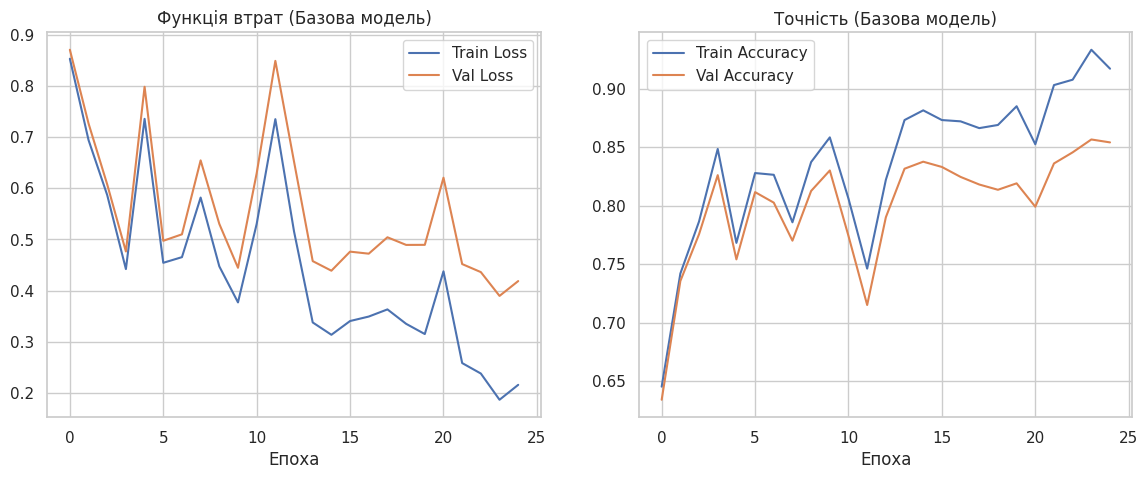

Максимальна різниця ймовірностей після відновлення: 0.00e+00
Збереження та відновлення ваг працює коректно!


In [5]:
ARCH = [784, 256, 128, 64, 10]
EPOCHS = 25
LR = 0.05
BATCH_SIZE = 64

# Збереження початкових ваг після He initialization для порівняння гістограм
init_model = MLP(ARCH, seed=SEED)
init_weights = np.concatenate([W.ravel() for W in init_model.weights[:-1]])

# Навчання базової моделі (без регуляризації)
base_model = MLP(ARCH, seed=SEED)
base_hist = train_model(base_model, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR)

# Графіки навчання (Loss та Accuracy)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(base_hist['train_loss'], label='Train Loss')
axes[0].plot(base_hist['val_loss'], label='Val Loss')
axes[0].set_title('Функція втрат (Базова модель)')
axes[0].set_xlabel('Епоха')
axes[0].legend()

axes[1].plot(base_hist['train_acc'], label='Train Accuracy')
axes[1].plot(base_hist['val_acc'], label='Val Accuracy')
axes[1].set_title('Точність (Базова модель)')
axes[1].set_xlabel('Епоха')
axes[1].legend()
plt.show()

# Перевірка збереження та відновлення ваг
base_model.save_weights('base_mlp_weights.npz')
restored_model = MLP(ARCH, seed=999) # інший seed, щоб гарантувати інші початкові ваги
restored_model.load_weights('base_mlp_weights.npz')

P_orig = base_model.forward(X_val, training=False)
P_rest = restored_model.forward(X_val, training=False)
max_diff = np.max(np.abs(P_orig - P_rest))
print(f"Максимальна різниця ймовірностей після відновлення: {max_diff:.2e}")
assert max_diff < 1e-7, "Помилка відновлення ваг!"
print("Збереження та відновлення ваг працює коректно!")

**Висновок:** За 25 епох модель досягла Train Acc = 0.9170, Val Acc = 0.8540, Val Loss = 0.4189.   
На графіках помітні типові для чистого SGD (без momentum) коливання функції втрат і точності, особливо в першій половині навчання (піки втрат на 4-й та 11-й епохах).   
Після 12–15 епохи розрив між Train Acc (91.7%) та Val Acc (~85.4%) стає стабільним (близько 6.3%), а Train Loss продовжує падати нижче 0.25, тоді як Val Loss коливається в межах 0.40–0.45. Це свідчить про помірне перенавчання (overfitting) базової моделі.   

## Блок 2. Дослідження впливу регуляризації
Запуск єдиного пайплайну експериментів для всіх методів регуляризації:
- Без регуляризації (Baseline)
- L2 регуляризація ($\lambda_2 \in \{10^{-4}, 10^{-3}\}$)
- L1 регуляризація ($\lambda_1 \in \{10^{-5}, 10^{-4}\}$)
- Dropout ($p \in \{0.1, 0.3, 0.5\}$)
- Weight clipping ($[-1, 1]$)
- Gradient clipping ($c \in \{1.0, 5.0\}$)
- Комбінована регуляризація (L2 $\lambda_2=10^{-4}$ + Dropout $p=0.2$)

In [6]:
experiments_config = {
    'Без регуляризації': {},
    'L2 (1e-4)': {'l2_lambda': 1e-4},
    'L2 (1e-3)': {'l2_lambda': 1e-3},
    'L1 (1e-5)': {'l1_lambda': 1e-5},
    'L1 (1e-4)': {'l1_lambda': 1e-4},
    'Dropout 0.1': {'dropout_p': 0.1},
    'Dropout 0.3': {'dropout_p': 0.3},
    'Dropout 0.5': {'dropout_p': 0.5},
    'Weight clipping [-1, 1]': {'weight_clip': 1.0},
    'Grad clipping (c=1.0)': {'grad_clip': 1.0},
    'Grad clipping (c=5.0)': {'grad_clip': 5.0},
    'L2 (1e-4) + Dropout 0.2': {'l2_lambda': 1e-4, 'dropout_p': 0.2},
}

results_summary = []
trained_models = {}
dead_tables = {}

for name, cfg in experiments_config.items():
    print(f"\n Експеримент: {name} ")
    model = MLP(ARCH, seed=SEED, **cfg)
    hist = train_model(model, X_train, y_train, X_val, y_val, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR)

    dead_df, dead_pct = diagnose_dead_neurons(model, X_train)
    sparsity_pct = compute_sparsity(model, threshold=0.01)

    trained_models[name] = model
    dead_tables[name] = dead_df

    # Додаткова перевірка для Weight clipping (скільки ваг досягли меж -1 або 1)
    if 'weight_clip' in cfg:
        all_w = np.concatenate([W.ravel() for W in model.weights])
        at_bounds = np.sum(np.abs(all_w) >= 1.0 - 1e-6)
        print(f"Кількість ваг на межах [-1, 1]: {at_bounds}")

    results_summary.append({
        'Метод': name,
        'Dead neurons, %': round(dead_pct, 2),
        'Sparsity, %': round(sparsity_pct, 2),
        'Val. accuracy': round(hist['val_acc'][-1], 4),
        'Val. loss': round(hist['val_loss'][-1], 4)
    })

summary_df = pd.DataFrame(results_summary)
print("\nПОРІВНЯЛЬНА ТАБЛИЦЯ")
display(summary_df)


 Експеримент: Без регуляризації 
Фінал (епоха 25): Train Acc=0.9170, Val Acc=0.8540, Val Loss=0.4189

 Експеримент: L2 (1e-4) 
Фінал (епоха 25): Train Acc=0.9223, Val Acc=0.8500, Val Loss=0.4516

 Експеримент: L2 (1e-3) 
Фінал (епоха 25): Train Acc=0.9112, Val Acc=0.8495, Val Loss=0.7654

 Експеримент: L1 (1e-5) 
Фінал (епоха 25): Train Acc=0.9167, Val Acc=0.8520, Val Loss=0.5268

 Експеримент: L1 (1e-4) 
Фінал (епоха 25): Train Acc=0.8975, Val Acc=0.8430, Val Loss=1.2175

 Експеримент: Dropout 0.1 
Фінал (епоха 25): Train Acc=0.9077, Val Acc=0.8535, Val Loss=0.3950

 Експеримент: Dropout 0.3 
Фінал (епоха 25): Train Acc=0.8914, Val Acc=0.8515, Val Loss=0.4050

 Експеримент: Dropout 0.5 
Фінал (епоха 25): Train Acc=0.8650, Val Acc=0.8360, Val Loss=0.4580

 Експеримент: Weight clipping [-1, 1] 
Фінал (епоха 25): Train Acc=0.9170, Val Acc=0.8540, Val Loss=0.4189
Кількість ваг на межах [-1, 1]: 0

 Експеримент: Grad clipping (c=1.0) 
Фінал (епоха 25): Train Acc=0.8870, Val Acc=0.8500, Va

,Метод,"Dead neurons, %","Sparsity, %",Val. accuracy,Val. loss
0,Без регуляризації,0.22,13.89,0.8540,0.4189
1,L2 (1e-4),0.00,14.12,0.8500,0.4516
2,L2 (1e-3),0.22,16.66,0.8495,0.7654
3,L1 (1e-5),0.00,16.24,0.8520,0.5268
4,L1 (1e-4),0.22,38.50,0.8430,1.2175
5,Dropout 0.1,0.00,13.89,0.8535,0.3950
6,Dropout 0.3,0.00,13.88,0.8515,0.4050
7,Dropout 0.5,0.00,13.99,0.8360,0.4580
8,"Weight clipping [-1, 1]",0.22,13.89,0.8540,0.4189
9,Grad clipping (c=1.0),1.12,14.24,0.8500,0.4396



2. L2-регуляризація ($\lambda_2 \in \{10^{-4}, 10^{-3}\}$) Результати: при $\lambda_2 = 10^{-4}$ — Val Acc = 0.8500, Val Loss = 0.4516; при $\lambda_2 = 10^{-3}$ — Val Acc = 0.8495, Val Loss = 0.7654.
Зростання Val Loss (до 0.7654 при $\lambda_2 = 10^{-3}$) відбувається частково через те, що до загальної функції втрат додається сам штраф $\frac{\lambda_2}{2}\Vert{}W\Vert{}_2^2$. На гістограмі L2 (1e-3) видно, що розподіл ваг став вужчим, а пік біля нуля — вищим порівняно з He-ініціалізацією: L2 плавно «стягує» великі ваги до нуля, не зануляючи їх повністю.   
3. L1-регуляризація ($\lambda_1 \in \{10^{-5}, 10^{-4}\}$) Результати: при $\lambda_1 = 10^{-5}$ — Val Acc = 0.8520, Val Loss = 0.5268; при $\lambda_1 = 10^{-4}$ — Val Acc = 0.8430, Val Loss = 1.2175.
На гістограмі L1 (1e-4) чітко видно різкий високий пік рівно в нулі (щільність > 22 проти ~7 у базової моделі). L1-штраф агресивно обнуляє слабкі зв’язки, створюючи високу розрідженість (sparsity). Проте при $\lambda_1 = 10^{-4}$ штраф уже занадто сильний: модель втрачає частину корисних ознак, що знижує як Train Acc (до 0.8975), так і Val Acc (до 0.8430).   
4. Dropout ($p \in \{0.1, 0.3, 0.5\}$)
Результати:Dropout 0.1: Train Acc = 0.9077, Val Acc = 0.8535, Val Loss = 0.3950 (найкращий показник функції втрат серед усіх експериментів).Dropout 0.3: Train Acc = 0.8914, Val Acc = 0.8515, Val Loss = 0.4050.Dropout 0.5: Train Acc = 0.8650, Val Acc = 0.8360, Val Loss = 0.4580.
Невеликий Dropout (0.1–0.3) ефективно зменшив розрив між Train та Val і знизив Val Loss нижче базового рівня (0.3950 проти 0.4189). Збільшення ймовірності до 0.5 призвело до недонавчання: за 25 епох мережа, в якій на кожному кроці вимикається половина нейронів, не встигає сформувати достатньо точні представлення, тому точність падає до 0.8360.
5. Weight Clipping ([-1, 1])
Результати: Train Acc = 0.9170, Val Acc = 0.8540, Val Loss = 0.4189 (ідентично базовій моделі), кількість ваг на межах [-1, 1]: 0.
Як видно з гістограм, усі ваги мережі (завдяки He-ініціалізації та нормалізації вхідних даних) протягом навчання залишалися в діапазоні приблизно [-0.35, 0.35]. Оскільки жодна вага не досягла меж -1 або 1, обмеження жодного разу не спрацювало, і піки біля меж на гістограмі відсутні. Для відчутного впливу weight clipping поріг мав би бути значно жорсткішим (наприклад, [-0.1, 0.1]), що, однак, обмежило б здатність моделі знаходити оптимальні параметри.   
6. Gradient Clipping ($c \in \{1.0, 5.0\}$)
Результати: c = 1.0 — Train Acc = 0.8870, Val Acc = 0.8500, Val Loss = 0.4396; c = 5.0 — Train Acc = 0.9196, Val Acc = 0.8510, Val Loss = 0.4066.
На відміну від weight clipping, gradient clipping обмежує величину кроку оновлення, а не самі ваги. При c = 5.0 обрізання згладило різкі стрибки градієнтів і покращило Val Loss (0.4066 проти 0.4189). При занадто жорсткому порозі c = 1.0 кроки SGD стали надто малими, що сповільнило збіжність (нижча Train Acc = 0.8870) і призвело до появи більшої частки мертвих нейронів (~1.1% на scatter plot).   
7. Комбінована регуляризація (L2 (1e-4) + Dropout 0.2)
Результати: Train Acc = 0.8957, Val Acc = 0.8500, Val Loss = 0.4630, Dead neurons = 0%.
Комбінація помітно зменшила перенавчання (розрив Train - Val скоротився з 6.3% до 4.57%) і повністю прибрала мертві нейрони (0%), але не перевершила окремий Dropout 0.1 за точністю чи Val Loss. Для 25 епох та обсягу вибірки 10 000 прикладів подвійне обмеження виявилося дещо надлишковим.

In [7]:
# таблиця мертвих нейронів по шарах для ключових методів
for name in ['Без регуляризації', 'L1 (1e-4)', 'L2 (1e-3)', 'Dropout 0.5', 'L2 (1e-4) + Dropout 0.2']:
    print(f"\nDead neurons по шарах — {name}:")
    display(dead_tables[name])


Dead neurons по шарах — Без регуляризації:


,Layer,Dead,Total,"Dead, %"
0,Hidden 1,0,256,0.0000
1,Hidden 2,0,128,0.0000
2,Hidden 3,1,64,1.5625



Dead neurons по шарах — L1 (1e-4):


,Layer,Dead,Total,"Dead, %"
0,Hidden 1,0,256,0.0000
1,Hidden 2,0,128,0.0000
2,Hidden 3,1,64,1.5625



Dead neurons по шарах — L2 (1e-3):


,Layer,Dead,Total,"Dead, %"
0,Hidden 1,0,256,0.0000
1,Hidden 2,0,128,0.0000
2,Hidden 3,1,64,1.5625



Dead neurons по шарах — Dropout 0.5:


,Layer,Dead,Total,"Dead, %"
0,Hidden 1,0,256,0.0
1,Hidden 2,0,128,0.0
2,Hidden 3,0,64,0.0



Dead neurons по шарах — L2 (1e-4) + Dropout 0.2:


,Layer,Dead,Total,"Dead, %"
0,Hidden 1,0,256,0.0
1,Hidden 2,0,128,0.0
2,Hidden 3,0,64,0.0


1. Діагностика мертвих нейронів (Dead Neurons)У базовій моделі, а також у моделях з L1 (1e-4) та L2 (1e-3) виявлено лише 1 мертвий нейрон у 3-му прихованому шарі (1.56% у шарі Hidden 3, або 0.22% від усіх 448 прихованих нейронів). У шарах Hidden 1 та Hidden 2 мертвих нейронів немає (0%). Такий низький показник пояснюється вдалим вибором He initialization та помірним learning_rate = 0.05. Застосування Dropout 0.5 та L2 (1e-4) + Dropout 0.2 повністю усунуло мертві нейрони (0% у всіх шарах), оскільки випадкове вимкнення нейронів під час навчання не дає окремим нейронам «застрягнути» в постійно від'ємній області ReLU.

## Аналіз та візуалізація результатів
1. Гістограми розподілу ваг прихованих шарів (початкові He vs Базова модель vs методи регуляризації).
2. Діаграма розсіювання (Scatter Plot): залежність `Val. accuracy` від `% Dead neurons`.

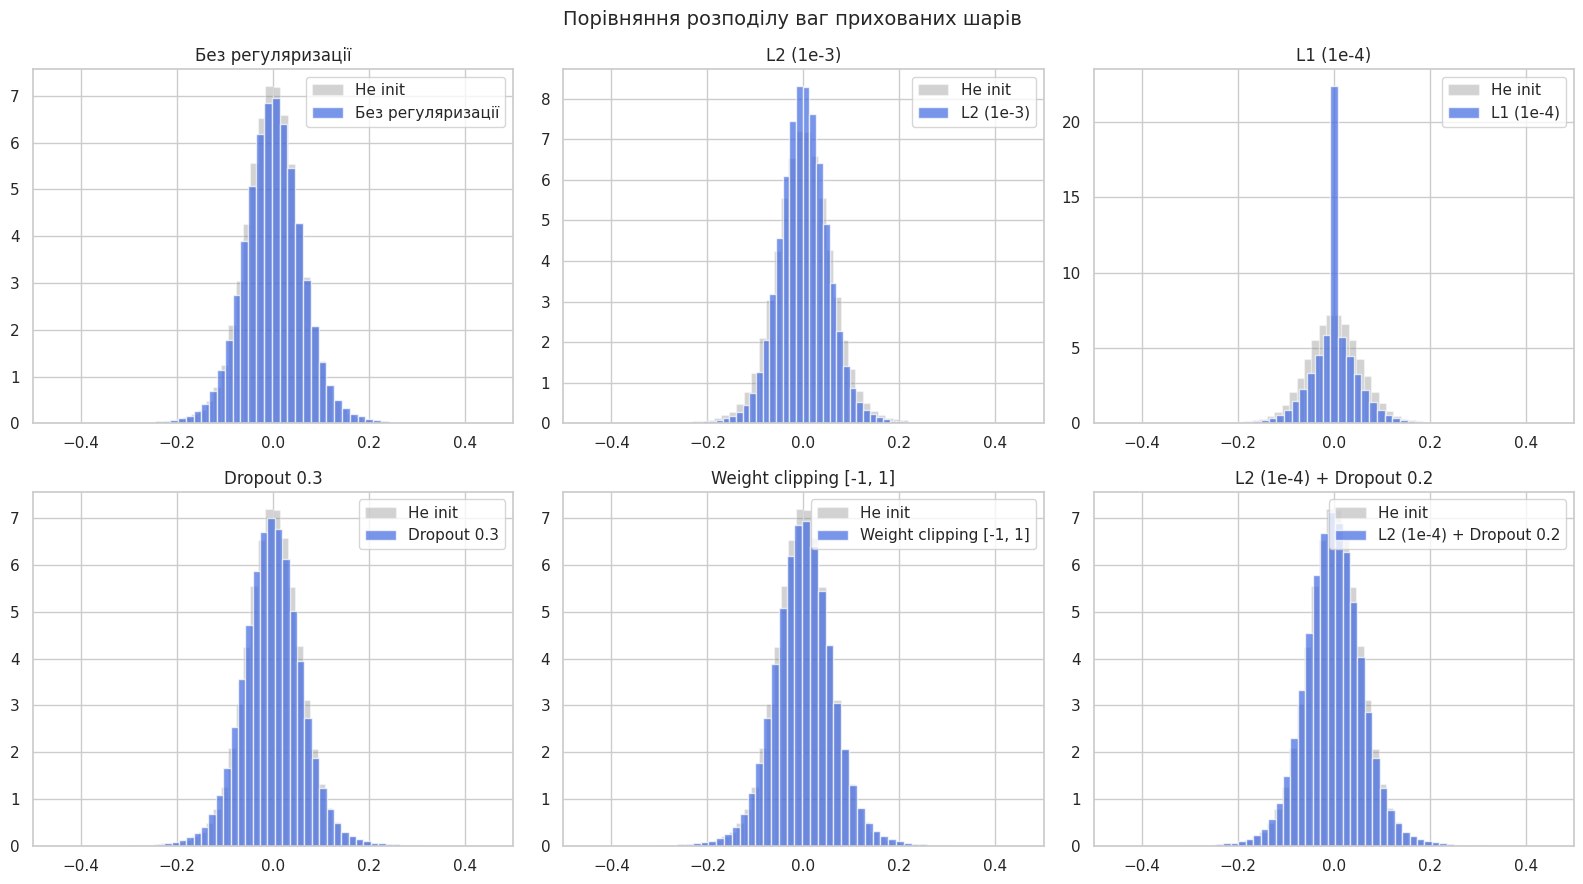

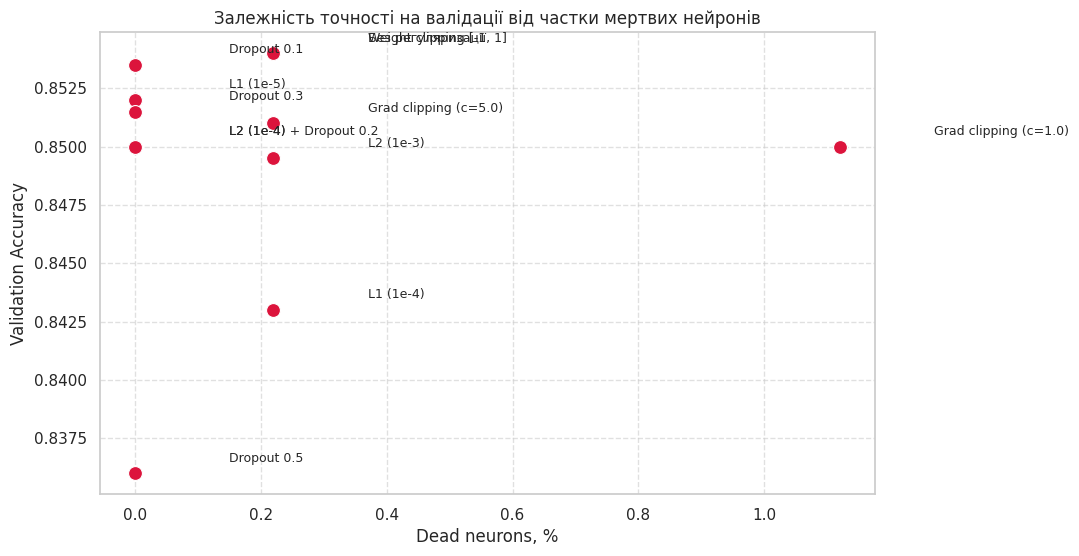

In [8]:
# Гістограми розподілу ваг
methods_to_plot = [
    'Без регуляризації', 'L2 (1e-3)', 'L1 (1e-4)',
    'Dropout 0.3', 'Weight clipping [-1, 1]', 'L2 (1e-4) + Dropout 0.2'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for idx, name in enumerate(methods_to_plot):
    model = trained_models[name]
    w_flat = np.concatenate([W.ravel() for W in model.weights[:-1]])

    axes[idx].hist(init_weights, bins=60, alpha=0.35, label='He init', density=True, color='gray')
    axes[idx].hist(w_flat, bins=60, alpha=0.7, label=name, density=True, color='royalblue')
    axes[idx].set_title(name)
    axes[idx].set_xlim(-0.5, 0.5)
    axes[idx].legend()

plt.suptitle('Порівняння розподілу ваг прихованих шарів', fontsize=14)
plt.tight_layout()
plt.show()

# Діаграма розсіювання: Dead neurons (%) vs Validation Accuracy
plt.figure(figsize=(10, 6))
sns.scatterplot(data=summary_df, x='Dead neurons, %', y='Val. accuracy', s=100, color='crimson')

for i, row in summary_df.iterrows():
    plt.text(row['Dead neurons, %'] + 0.15, row['Val. accuracy'] + 0.0005, row['Метод'], fontsize=9)

plt.title('Залежність точності на валідації від частки мертвих нейронів')
plt.xlabel('Dead neurons, %')
plt.ylabel('Validation Accuracy')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Висновок:**
1. Розподіл ваг (Гістограми)   
- Без регуляризації / Dropout / Weight clipping: Розподіл ваг майже повторює початковий нормальний розподіл He init із легким розширенням хвостів під час навчання.
- L2 (1e-3): Розподіл помітно звузився до центру, що зменшує дисперсію ваг без створення жорстких нулів.
- L1 (1e-4): Єдиний метод, який радикально змінив форму розподілу — утворився вузький високий пік у точці 0, що візуально підтверджує високу розрідженість (sparsity).
2. Залежність мертвих нейронів від точності (Scatter Plot)   
- Чи існує пряма залежність? Ні, на графіку відсутня чітка лінійна кореляція між % Dead neurons та Val. accuracy.   
- Чи можуть моделі з однаковою кількістю мертвих нейронів мати різну точність? Так. При 0.0% мертвих нейронів Dropout 0.1 дає 0.8535, а Dropout 0.5 — лише 0.8360. Аналогічно при 0.22% мертвих нейронів точність коливається від 0.8430 (L1 1e-4) до 0.8540 (Без регуляризації).   

У даній архітектурі частка мертвих нейронів занадто мала (до 1.12%), щоб суттєво впливати на точність; головним чинником якості є баланс між перенавчанням і недонавчанням.

3. Чи завжди збільшення сили регуляризації покращує узагальнювальну здатність? - Ні, експерименти показали, що слабка/помірна регуляризація (Dropout 0.1, Grad clipping c=5.0) покращує стабільність і знижує Val Loss (0.3950 проти 0.4189), не втрачаючи точності. Натомість сильна регуляризація (Dropout 0.5, L1 1e-4, L2 1e-3) призводить до недонавчання — падає точність як на тренувальній, так і на валідаційній вибірках.